# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Sandi Suryo Nugroho | 5054251020 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from kneed import KneeLocator

sns.set_style('whitegrid')
RANDOM_STATE = 42
N_INIT = 10


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv', encoding='utf-8-sig')

print('Jumlah baris dan kolom:', df.shape)
print()
df.info()
print('\nStatistik deskriptif:')
display(df.describe().T)
print('Missing value per kolom:')
print(df.isna().sum())
print('\nJumlah baris duplikat (seluruh kolom sama):', df.duplicated().sum())
print('Jumlah status_id duplikat:', df['status_id'].duplicated().sum(), '(status_id selalu unik)')
cols_wo_id = [c for c in df.columns if c != 'status_id']
print('Jumlah baris duplikat jika status_id diabaikan:', df.duplicated(subset=cols_wo_id).sum())
empty_cols = [c for c in df.columns if df[c].isna().all()]
print('Kolom yang seluruhnya kosong:', empty_cols if empty_cols else 'tidak ada')


Jumlah baris dan kolom: (7050, 16)

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), in

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Missing value per kolom:
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Jumlah baris duplikat (seluruh kolom sama): 0
Jumlah status_id duplikat: 0 (status_id selalu unik)
Jumlah baris duplikat jika status_id diabaikan: 54
Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


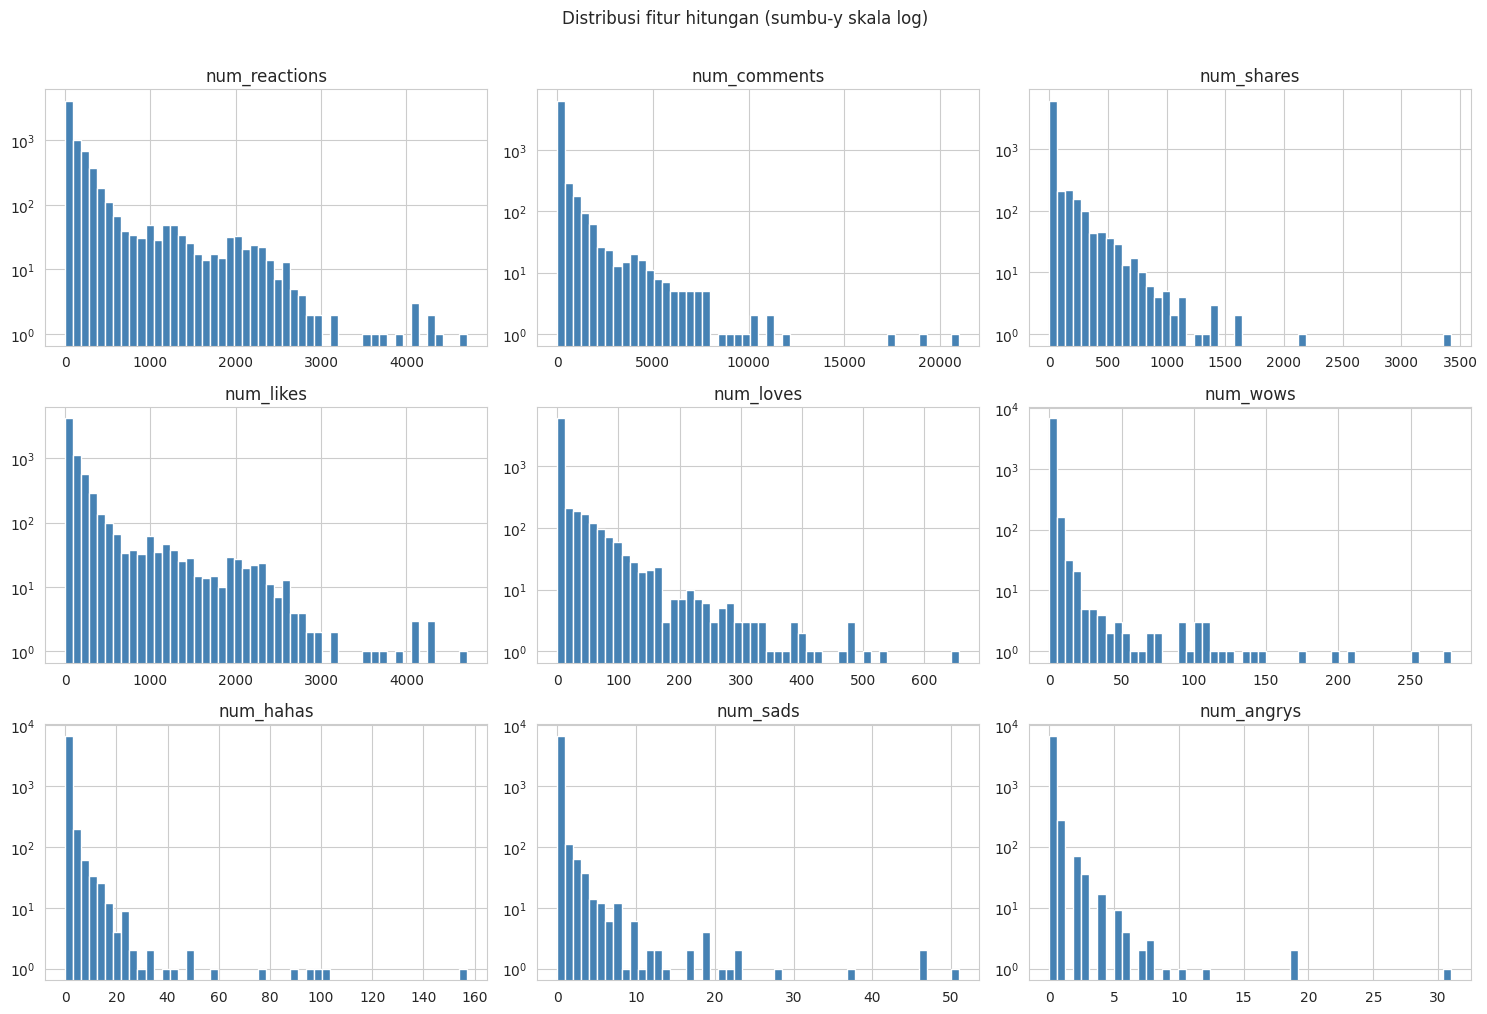

,skewness,proporsi_nol,median,maks
num_reactions,3.738,0.017,59.5,4710
num_comments,9.029,0.301,4.0,20990
num_shares,7.099,0.555,0.0,3424
num_likes,3.919,0.018,58.0,4710
num_loves,6.005,0.600,0.0,657
num_wows,18.247,0.753,0.0,278
num_hahas,20.306,0.839,0.0,157
num_sads,17.579,0.914,0.0,51
num_angrys,19.507,0.940,0.0,31


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes',
              'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), count_cols):
    ax.hist(df[c], bins=50, color='steelblue')
    ax.set_title(c)
    ax.set_yscale('log')
plt.suptitle('Distribusi fitur hitungan (sumbu-y skala log)', y=1.01)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'skewness': df[count_cols].skew(),
    'proporsi_nol': (df[count_cols] == 0).mean(),
    'median': df[count_cols].median(),
    'maks': df[count_cols].max()
}).round(3)
display(summary)


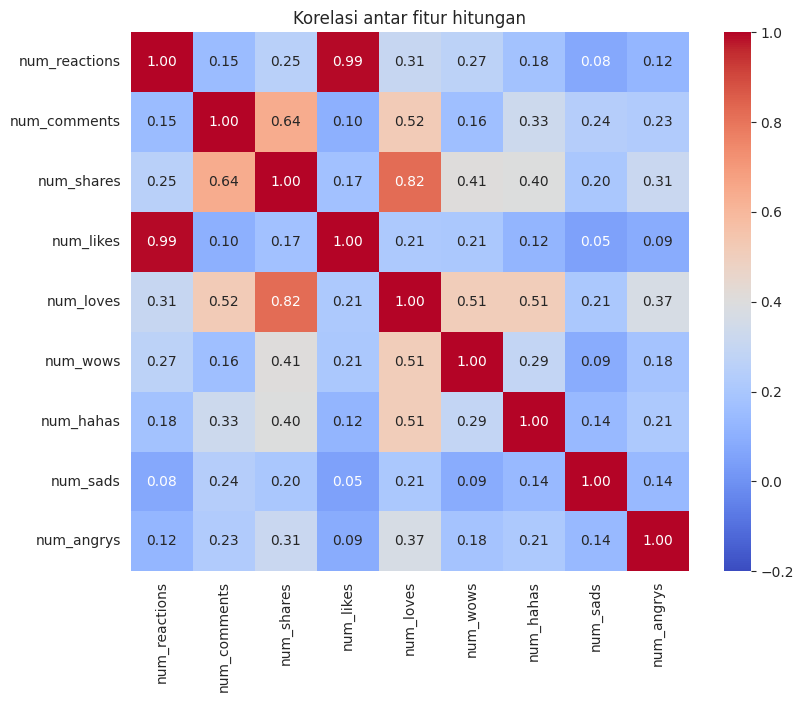

Proporsi baris dengan num_reactions == num_likes + semua emoji: 0.9987


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.2, vmax=1)
plt.title('Korelasi antar fitur hitungan')
plt.show()

# Cek redundansi secara definisi: apakah num_reactions = jumlah semua reaksi?
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
sum_reactions = df['num_likes'] + df[emoji_cols].sum(axis=1)
print('Proporsi baris dengan num_reactions == num_likes + semua emoji:', (sum_reactions == df['num_reactions']).mean().round(4))


,jumlah_posting,proporsi_ada_emoji
year,,
2012,589,0.000
2013,500,0.000
2014,233,0.000
2015,337,0.000
2016,588,0.680
2017,2253,0.542
2018,2550,0.578


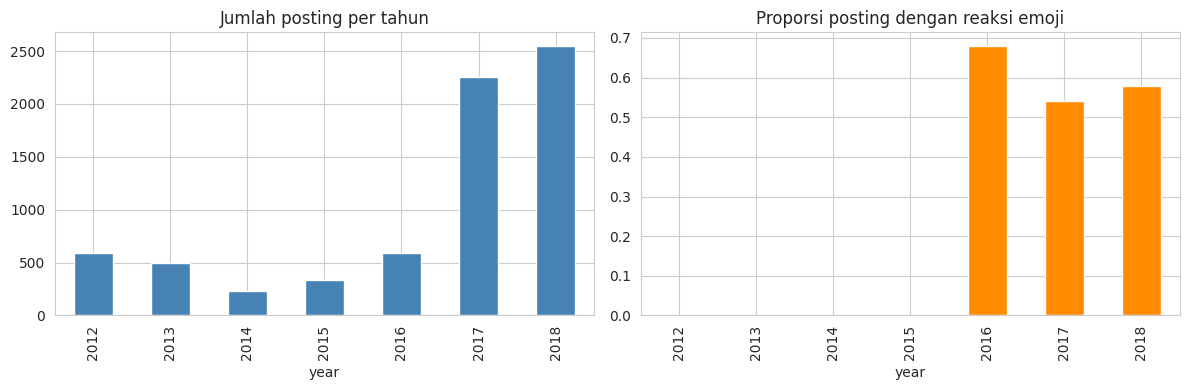

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'], format='%m/%d/%Y %H:%M')
df['year'] = df['status_published'].dt.year
df['has_emoji'] = df[emoji_cols].sum(axis=1) > 0

yearly = df.groupby('year').agg(jumlah_posting=('status_id', 'count'),
                                proporsi_ada_emoji=('has_emoji', 'mean')).round(3)
display(yearly)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
yearly['jumlah_posting'].plot(kind='bar', ax=ax[0], color='steelblue', title='Jumlah posting per tahun')
yearly['proporsi_ada_emoji'].plot(kind='bar', ax=ax[1], color='darkorange', title='Proporsi posting dengan reaksi emoji')
plt.tight_layout()
plt.show()


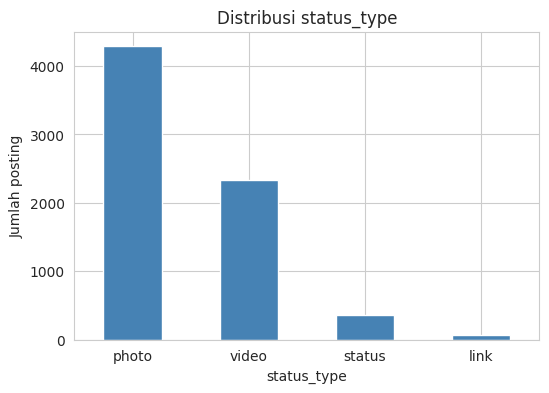

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
fig, ax = plt.subplots(figsize=(6, 4))
df['status_type'].value_counts().plot(kind='bar', color='steelblue', ax=ax)
ax.set_title('Distribusi status_type')
ax.set_ylabel('Jumlah posting')
plt.xticks(rotation=0)
plt.show()

display(df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median())


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [7]:
# EDA tambahan 1: median engagement per tahun dan status_type
tmp = df.copy()
tmp['year'] = pd.to_datetime(tmp['status_published'], format='%m/%d/%Y %H:%M').dt.year
display(tmp.pivot_table(index='year', columns='status_type', values='num_reactions', aggfunc='median'))
display(tmp.pivot_table(index='year', columns='status_type', values='status_id', aggfunc='count'))


status_type,link,photo,status,video
year,,,,
2012,NaN,19.0,NaN,NaN
2013,NaN,48.0,35.5,167.0
2014,37.0,41.0,NaN,471.0
2015,1277.0,1649.0,1230.0,2020.0
2016,47.0,167.0,83.0,124.5
2017,48.0,30.0,66.5,95.5
2018,8.5,29.0,170.0,156.0


status_type,link,photo,status,video
year,,,,
2012,NaN,589.0,NaN,NaN
2013,NaN,404.0,2.0,94.0
2014,1.0,25.0,NaN,207.0
2015,14.0,202.0,79.0,42.0
2016,14.0,403.0,51.0,120.0
2017,18.0,1269.0,122.0,844.0
2018,16.0,1396.0,111.0,1027.0


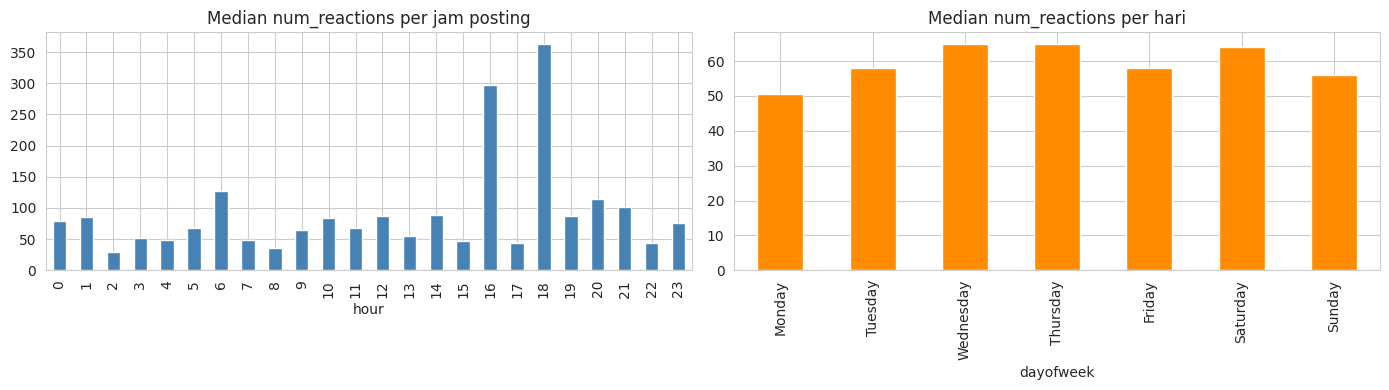

In [8]:
# EDA tambahan 2: pola waktu posting (jam dan hari) dan median engagement
df['hour'] = df['status_published'].dt.hour
df['dayofweek'] = df['status_published'].dt.day_name()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby('hour')['num_reactions'].median().plot(kind='bar', ax=ax[0], color='steelblue', title='Median num_reactions per jam posting')
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df.groupby('dayofweek')['num_reactions'].median().reindex(order).plot(kind='bar', ax=ax[1], color='darkorange', title='Median num_reactions per hari')
plt.tight_layout()
plt.show()


Kuantil fitur hitungan utama:


,num_comments,num_shares,num_likes
0.500,4.000,0.00,58.000
0.900,508.100,136.00,496.100
0.990,4338.040,607.00,2297.000
0.999,10168.605,1326.57,3909.739
1.000,20990.000,3424.00,4710.000


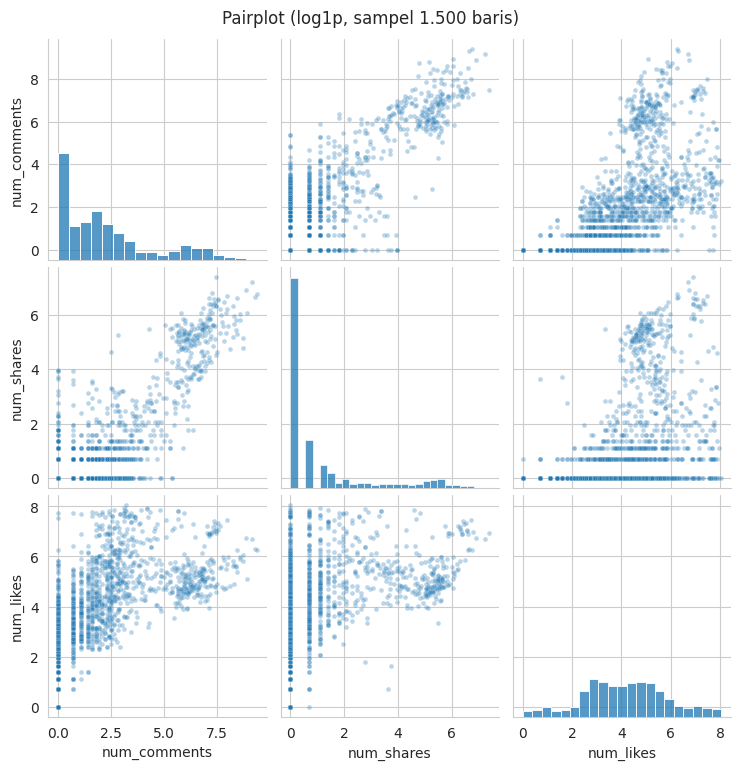

In [9]:
# EDA tambahan 3: hubungan antar fitur utama (skala log) dan outlier ekstrem
print('Kuantil fitur hitungan utama:')
display(df[['num_comments', 'num_shares', 'num_likes']].quantile([0.5, 0.9, 0.99, 0.999, 1.0]))
sns.pairplot(np.log1p(df[['num_comments', 'num_shares', 'num_likes']]).sample(1500, random_state=RANDOM_STATE),
             plot_kws={'alpha': 0.3, 's': 12})
plt.suptitle('Pairplot (log1p, sampel 1.500 baris)', y=1.02)
plt.show()


**Temuan EDA tambahan:**
- Reaksi emoji baru ada sejak 2016. Pada 2012-2015 proporsi posting dengan emoji 0%, lalu sekitar 54-68% pada 2016-2018. Jadi nilai nol pada kolom emoji sebagian besar berarti "fitur belum tersedia", bukan "tidak ada engagement".
- Posting tahun 2015 punya median `num_reactions` sangat tinggi (sekitar 1.200-2.000 untuk link, photo, status, dan video), padahal jumlah posting tahun itu sedikit (337). Ini kemungkinan kumpulan posting viral atau kondisi khusus halaman tertentu dan perlu diingat saat membaca cluster.
- Video punya median komentar dan share tertinggi di semua `status_type`. Photo mendominasi jumlah posting (sekitar 69%) tetapi median komentar dan share-nya rendah.
- 55,8% posting memiliki `num_shares = 0` dan 30,2% memiliki `num_comments = 0`, sementara nilai maksimumnya sangat jauh (komentar 20.990, share 3.424). Distribusi sangat miring ke kanan.
- Setelah `status_id` diabaikan, ada 54 baris yang identik pada seluruh kolom lain (waktu posting dan semua metrik). Baris ini dianggap duplikat pada tahap preprocessing.

# 2. Preprocessing

In [10]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
# 1. Kolom kosong
empty_cols = [c for c in df.columns if df[c].isna().all()]
df_clean = df.drop(columns=empty_cols).copy()
print('Kolom kosong yang dihapus:', empty_cols if empty_cols else 'tidak ada')

# 2. Duplikat: status_id selalu unik (hanya nomor urut), jadi duplikat harus dicari
#    dari seluruh kolom lain (waktu posting + semua metrik engagement identik)
n_before = len(df_clean)
cols_wo_id = [c for c in df_clean.columns if c != 'status_id']
print('status_id unik:', df_clean['status_id'].is_unique)
print('Baris duplikat (kolom selain status_id sama):', df_clean.duplicated(subset=cols_wo_id).sum())
df_clean = df_clean.drop_duplicates(subset=cols_wo_id, keep='first').reset_index(drop=True)
print(f'Baris sebelum: {n_before}, sesudah: {len(df_clean)} (dibuang: {n_before - len(df_clean)})')

# 3. Missing value
print('\nTotal missing value setelah pembersihan:', df_clean.isna().sum().sum())

# 4. Outlier ekstrem: tidak dibuang (outlier = posting viral, bagian dari pola engagement),
#    ditangani lewat transformasi log1p + scaling.
Q = df_clean[['num_comments', 'num_shares', 'num_likes']]
iqr_outlier = ((Q > (Q.quantile(0.75) + 1.5 * (Q.quantile(0.75) - Q.quantile(0.25))))).mean().round(3)
print('\nProporsi nilai di atas batas IQR (Q3 + 1.5*IQR):')
print(iqr_outlier)
print('\nNilai maksimum vs median:')
display(pd.DataFrame({'median': Q.median(), 'maks': Q.max()}))


Kolom kosong yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']
status_id unik: True
Baris duplikat (kolom selain status_id sama): 54
Baris sebelum: 7050, sesudah: 6996 (dibuang: 54)

Total missing value setelah pembersihan: 0

Proporsi nilai di atas batas IQR (Q3 + 1.5*IQR):
num_comments    0.195
num_shares      0.198
num_likes       0.108
dtype: float64

Nilai maksimum vs median:


,median,maks
num_comments,4.0,20990
num_shares,0.0,3424
num_likes,57.0,4710


In [11]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
# Metadata untuk interpretasi (tidak dipakai sebagai fitur)
meta = df_clean[['status_id', 'status_type', 'status_published']].copy()

# Hanya kolom hitungan yang dipakai; status_id, status_type, status_published dibuang dari fitur
features_all = df_clean[count_cols].copy()

# Redundansi: num_reactions = likes + semua emoji
match = (features_all['num_reactions'] == features_all['num_likes'] + features_all[emoji_cols].sum(axis=1))
print(f'Proporsi baris dengan num_reactions == likes + emoji: {match.mean():.4f}')

# Proporsi nol tiap kolom
print('\nProporsi nilai nol:')
print((features_all == 0).mean().round(3))

# Gabungkan emoji yang sparse
features_all['num_emoji'] = features_all[emoji_cols].sum(axis=1)

selected = ['num_comments', 'num_shares', 'num_likes', 'num_emoji']
X = features_all[selected].copy()
print('\nFitur terpilih:', selected, '| shape:', X.shape)
print('Tipe data semua numerik:', all(np.issubdtype(t, np.number) for t in X.dtypes))
display(X.describe().T)


Proporsi baris dengan num_reactions == likes + emoji: 0.9987

Proporsi nilai nol:
num_reactions    0.017
num_comments     0.302
num_shares       0.558
num_likes        0.018
num_loves        0.604
num_wows         0.757
num_hahas        0.840
num_sads         0.915
num_angrys       0.940
dtype: float64

Fitur terpilih: ['num_comments', 'num_shares', 'num_likes', 'num_emoji'] | shape: (6996, 4)
Tipe data semua numerik: True


,count,mean,std,min,25%,50%,75%,max
num_comments,6996.0,225.648799,892.922206,0.0,0.0,4.0,22.25,20990.0
num_shares,6996.0,40.275872,132.072584,0.0,0.0,0.0,4.00,3424.0
num_likes,6996.0,210.036735,439.623067,0.0,17.0,57.0,182.00,4710.0
num_emoji,6996.0,15.051601,47.953856,0.0,0.0,0.0,5.00,886.0


**Fitur yang dipilih untuk clustering:** `num_comments`, `num_shares`, `num_likes`, dan `num_emoji`.

- **`num_reactions` dibuang.** Kolom ini hampir selalu sama dengan `num_likes` + semua emoji (cocok pada 99,87% baris), sehingga redundan. Jika dipakai bersama komponen penyusunnya, engagement "reaksi" terhitung dua kali dan bobotnya terlalu besar pada jarak Euclidean.
- **Emoji digabung menjadi `num_emoji`** (= loves + wows + hahas + sads + angrys). Masing-masing kolom emoji sangat sparse (nol pada 60% sampai 94% baris, dan tidak ada sama sekali sebelum 2016). Bila dipakai terpisah, kolom-kolom itu hanya menambah dimensi yang hampir konstan dan banyak berisi noise. Setelah digabung, kolom ini tetap membawa informasi intensitas reaksi emosional.
- `num_likes` dipertahankan terpisah dari emoji karena merupakan reaksi dasar yang hampir selalu ada (hanya 1,8% bernilai nol).
- `num_comments` dan `num_shares` dipertahankan karena menggambarkan keterlibatan yang lebih aktif dibandingkan sekadar reaksi.
- `status_type`, `status_published`, dan `status_id` tidak dipakai sebagai fitur. Dua yang pertama hanya dipakai untuk interpretasi cluster, sedangkan `status_id` hanya nomor urut.
- Empat kolom `Column1` sampai `Column4` dibuang karena seluruhnya kosong, dan 54 baris duplikat dibuang (tersisa 6.996 baris).

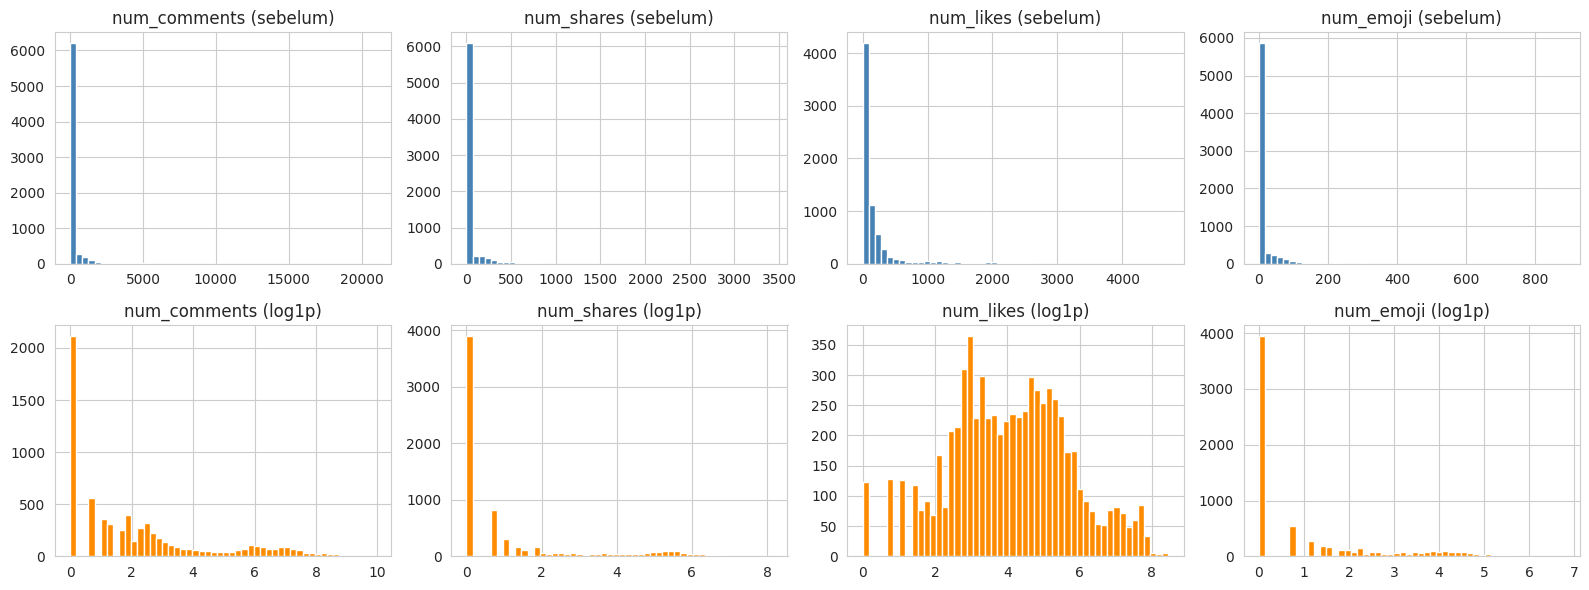

,skew_sebelum,skew_sesudah
num_comments,8.99,1.05
num_shares,7.07,1.53
num_likes,3.93,-0.01
num_emoji,6.97,1.31


In [12]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(selected):
    axes[0, i].hist(X[c], bins=50, color='steelblue')
    axes[0, i].set_title(f'{c} (sebelum)')
    axes[1, i].hist(X_log[c], bins=50, color='darkorange')
    axes[1, i].set_title(f'{c} (log1p)')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'skew_sebelum': X.skew(), 'skew_sesudah': X_log.skew()}).round(2))


In [13]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

X_raw = X.values
X_raw_scaled = StandardScaler().fit_transform(X)

print('X_raw        :', X_raw.shape, '| std per fitur:', X_raw.std(axis=0).round(1))
print('X_raw_scaled :', X_raw_scaled.shape, '| std per fitur:', X_raw_scaled.std(axis=0).round(2))
print('X_log_scaled :', X_log_scaled.shape, '| std per fitur:', X_log_scaled.std(axis=0).round(2))


X_raw        : (6996, 4) | std per fitur: [892.9 132.1 439.6  48. ]
X_raw_scaled : (6996, 4) | std per fitur: [1. 1. 1. 1.]
X_log_scaled : (6996, 4) | std per fitur: [1. 1. 1. 1.]


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [14]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
K_COMPARE = 3
versions = {'(1) X_raw': X_raw, '(2) X_raw_scaled': X_raw_scaled, '(3) X_log_scaled': X_log_scaled}
labels_cmp = {}
for name, data in versions.items():
    km = KMeans(n_clusters=K_COMPARE, random_state=RANDOM_STATE, n_init=N_INIT)
    labels_cmp[name] = km.fit_predict(data)
print('Selesai melatih 3 model K-Means dengan k =', K_COMPARE)


Selesai melatih 3 model K-Means dengan k = 3


In [15]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
rows = []
for name, lab in labels_cmp.items():
    sizes = np.bincount(lab)
    rows.append({'Versi data': name,
                 'Ukuran cluster': sizes.tolist(),
                 'Cluster terkecil': sizes.min(),
                 'Cluster terbesar': sizes.max(),
                 'Silhouette (ruang X_log_scaled)': round(silhouette_score(X_log_scaled, lab), 4)})
display(pd.DataFrame(rows))

print('Varians tiap fitur pada data mentah (tanpa scaling):')
print(pd.Series(X_raw.var(axis=0), index=selected).round(1))
print('\nKontribusi varians (%):')
print((pd.Series(X_raw.var(axis=0), index=selected) / X_raw.var(axis=0).sum() * 100).round(2))


,Versi data,Ukuran cluster,Cluster terkecil,Cluster terbesar,Silhouette (ruang X_log_scaled)
0,(1) X_raw,"[6392, 137, 467]",137,6392,0.2731
1,(2) X_raw_scaled,"[373, 6277, 346]",346,6277,0.2533
2,(3) X_log_scaled,"[1131, 2258, 3607]",1131,3607,0.4638


Varians tiap fitur pada data mentah (tanpa scaling):
num_comments    797196.1
num_shares       17440.7
num_likes       193240.8
num_emoji         2299.2
dtype: float64

Kontribusi varians (%):
num_comments    78.92
num_shares       1.73
num_likes       19.13
num_emoji        0.23
dtype: float64


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [16]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = range(2, 11)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_log_scaled)
    inertias.append(km.inertia_)
pd.DataFrame({'k': list(k_range), 'inertia': np.round(inertias, 1)})


,k,inertia
0,2,11586.9
1,3,6779.8
2,4,5678.3
3,5,4740.0
4,6,4220.3
5,7,3772.1
6,8,3418.6
7,9,3116.4
8,10,2899.1


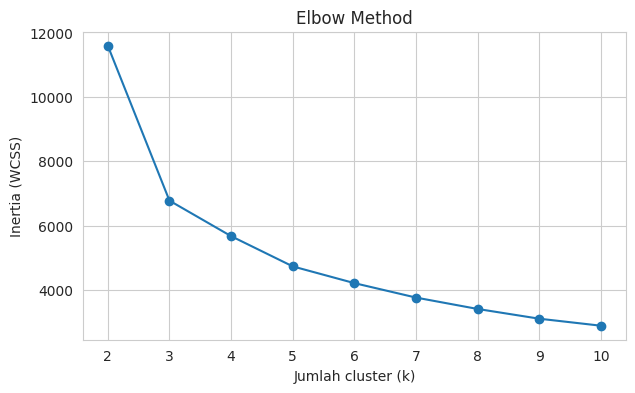

Elbow otomatis (KneeLocator): 4


In [17]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(7, 4))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel('Jumlah cluster (k)'); plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.xticks(list(k_range))
plt.show()

knee = KneeLocator(list(k_range), inertias, curve='convex', direction='decreasing')
print('Elbow otomatis (KneeLocator):', knee.elbow)


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [18]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = {}
for k in k_range:
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, lab)
pd.Series(sil_scores, name='silhouette').round(4).to_frame()


,silhouette
2,0.5899
3,0.4638
4,0.3372
5,0.3586
6,0.3469
7,0.3367
8,0.3154
9,0.3293
10,0.3160


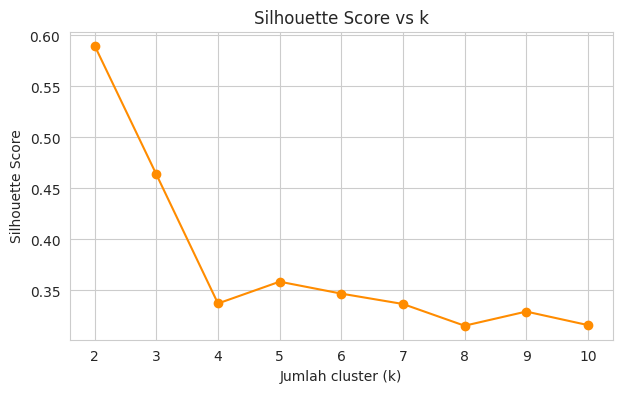

k dengan Silhouette tertinggi: 2


In [19]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='darkorange')
plt.xlabel('Jumlah cluster (k)'); plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k')
plt.xticks(list(k_range))
plt.show()
print('k dengan Silhouette tertinggi:', max(sil_scores, key=sil_scores.get))


**Pilihan k untuk K-Means: k = 3**

- **Elbow:** inertia turun paling tajam dari k=2 ke k=3 (11.587 menjadi 6.780, turun sekitar 41%). Setelah itu penurunannya landai dan relatif stabil, yaitu sekitar 1.100 untuk k=3 ke k=4 dan sekitar 940 untuk k=4 ke k=5. Secara visual siku ada di k=3. `KneeLocator` mendeteksi k=4, jadi hasilnya sedikit berbeda dari pengamatan saya karena kurvanya melengkung halus.
- **Silhouette:** tertinggi pada k=2 (0,590), lalu k=3 (0,464), dan turun jauh ke k=4 (0,337). Nilai k=3 masih tergolong baik (struktur cukup jelas).
- **Keputusan:** saya memilih k=3 sebagai kompromi. Elbow mendukung k=3, Silhouette k=3 masih tinggi, dan k=3 memberi hasil yang bermakna secara bisnis (posting viral, posting dengan like banyak, dan posting sepi). Dengan k=2, kelompok viral dan kelompok like banyak menyatu sehingga perbedaan polanya hilang. Dendrogram Ward (bagian 4.1) juga mendukung pemotongan pada 3 cluster.

## 3.4 Model K-Means Final

In [20]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
K_BEST = 3
kmeans_final = KMeans(n_clusters=K_BEST, random_state=RANDOM_STATE, n_init=N_INIT)
labels_km = kmeans_final.fit_predict(X_log_scaled)
print('Ukuran cluster K-Means:', dict(zip(*np.unique(labels_km, return_counts=True))))


Ukuran cluster K-Means: {np.int32(0): np.int64(1131), np.int32(1): np.int64(2258), np.int32(2): np.int64(3607)}


In [21]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
def profile_clusters(labels):
    d = df_clean[count_cols].copy()
    d['cluster'] = labels
    med = d.groupby('cluster')[count_cols].median()
    mean = d.groupby('cluster')[count_cols].mean().round(1)
    size = d['cluster'].value_counts().sort_index().rename('jumlah_posting')
    return med, mean, size

med_km, mean_km, size_km = profile_clusters(labels_km)
print('Jumlah anggota:'); display(size_km.to_frame())
print('Median fitur per cluster (data asli):'); display(med_km)
print('Rata-rata fitur per cluster (data asli):'); display(mean_km)


Jumlah anggota:


,jumlah_posting
cluster,
0,1131
1,2258
2,3607


Median fitur per cluster (data asli):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
cluster,,,,,,,,,
0,238.0,722.0,178.0,170.0,51.0,1.0,2.0,0.0,0.0
1,211.0,11.0,1.0,206.0,1.0,0.0,0.0,0.0,0.0
2,18.0,0.0,0.0,18.0,0.0,0.0,0.0,0.0,0.0


Rata-rata fitur per cluster (data asli):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
cluster,,,,,,,,,
0,387.8,1335.4,238.0,304.5,72.8,5.4,3.7,0.8,0.5
1,467.3,26.9,4.7,462.7,2.8,1.1,0.3,0.3,0.1
2,22.5,2.1,0.5,22.2,0.1,0.0,0.0,0.0,0.0


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [22]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')
print('Bentuk linkage matrix:', Z.shape)


Bentuk linkage matrix: (6995, 4)


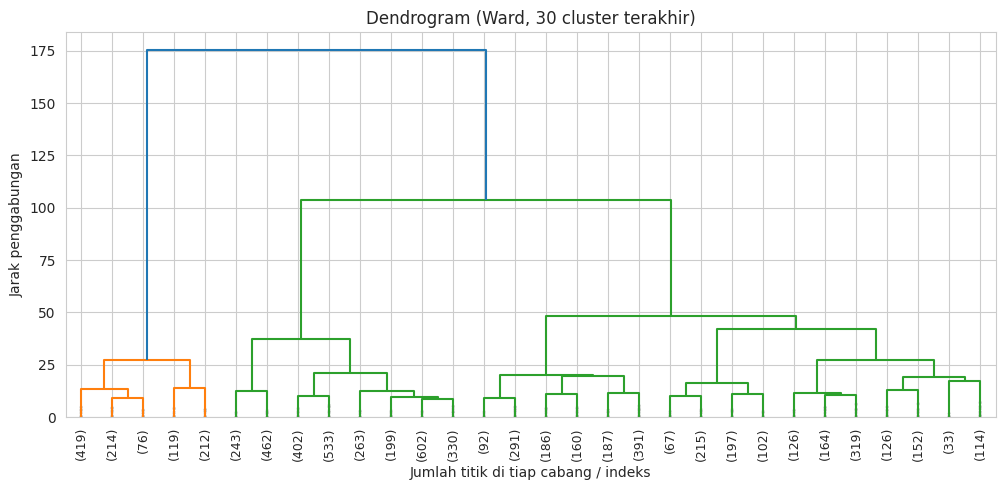

Jarak 10 penggabungan terakhir: [ 19.4  20.2  21.1  27.4  27.5  37.5  42.3  48.4 103.7 175.1]
Selisih antar penggabungan   : [ 0.8  0.9  6.3  0.1 10.1  4.8  6.1 55.3 71.4]


In [23]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title('Dendrogram (Ward, 30 cluster terakhir)')
plt.xlabel('Jumlah titik di tiap cabang / indeks'); plt.ylabel('Jarak penggabungan')
plt.show()

# Lonjakan jarak pada 10 penggabungan terakhir membantu menentukan titik potong
last = Z[-10:, 2]
print('Jarak 10 penggabungan terakhir:', last.round(1))
print('Selisih antar penggabungan   :', np.diff(last).round(1))


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [24]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
N_CLUSTERS_HC = 3
linkages = ['ward', 'complete', 'average', 'single']
labels_link = {}
for lk in linkages:
    labels_link[lk] = AgglomerativeClustering(n_clusters=N_CLUSTERS_HC, linkage=lk).fit_predict(X_log_scaled)
print('Selesai melatih Agglomerative Clustering dengan n_clusters =', N_CLUSTERS_HC)


Selesai melatih Agglomerative Clustering dengan n_clusters = 3


In [25]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
rows = []
for lk, lab in labels_link.items():
    sizes = np.bincount(lab)
    rows.append({'Linkage': lk,
                 'Silhouette': round(silhouette_score(X_log_scaled, lab), 4),
                 'Ukuran cluster': sorted(sizes.tolist(), reverse=True),
                 'Cluster terkecil': sizes.min(),
                 'Cluster terbesar': sizes.max()})
link_table = pd.DataFrame(rows).set_index('Linkage')
display(link_table)


,Silhouette,Ukuran cluster,Cluster terkecil,Cluster terbesar
Linkage,,,,
ward,0.4201,"[3034, 2922, 1040]",1040,3034
complete,0.1163,"[5775, 761, 460]",460,5775
average,0.5069,"[5764, 1197, 35]",35,5764
single,0.3139,"[6994, 1, 1]",1,6994


**Pilihan linkage untuk Hierarchical Clustering: Ward**

Pada n_clusters = 3, Silhouette: average 0,507 > ward 0,420 > single 0,314 > complete 0,116.

- **Average** punya Silhouette tertinggi, tetapi ukuran clusternya sangat timpang [5.764, 1.197, 35]. Satu cluster hanya berisi 35 titik, sehingga skor tinggi itu hanya karena cluster kecil berisi outlier terpisah, bukan karena segmentasi yang berguna.
- **Single** menghasilkan [6.994, 1, 1]: dua titik outlier menjadi cluster sendiri dan sisanya satu cluster raksasa (efek *chaining*), jadi tidak berguna untuk segmentasi.
- **Complete** hanya 0,116 dan satu cluster berisi 5.775 titik, karena sensitif terhadap outlier.
- **Ward** menghasilkan tiga cluster yang seimbang ([3.034, 2.922, 1.040]) dengan Silhouette 0,420 dan paling mirip K-Means dalam arti meminimalkan varians dalam cluster. Saya memilih Ward.

## 4.3 Model Hierarchical Clustering Final

In [26]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
BEST_LINKAGE = 'ward'
hc_final = AgglomerativeClustering(n_clusters=K_BEST, linkage=BEST_LINKAGE)
labels_hc = hc_final.fit_predict(X_log_scaled)
print('Linkage:', BEST_LINKAGE, '| n_clusters:', K_BEST)
print('Ukuran cluster HC:', dict(zip(*np.unique(labels_hc, return_counts=True))))


Linkage: ward | n_clusters: 3
Ukuran cluster HC: {np.int64(0): np.int64(2922), np.int64(1): np.int64(1040), np.int64(2): np.int64(3034)}


In [27]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
med_hc, mean_hc, size_hc = profile_clusters(labels_hc)
print('Jumlah anggota:'); display(size_hc.to_frame())
print('Median fitur per cluster (data asli):'); display(med_hc)
print('Rata-rata fitur per cluster (data asli):'); display(mean_hc)


Jumlah anggota:


,jumlah_posting
cluster,
0,2922
1,1040
2,3034


Median fitur per cluster (data asli):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
cluster,,,,,,,,,
0,154.0,9.0,1.0,150.0,1.0,0.0,0.0,0.0,0.0
1,235.0,815.5,193.5,168.0,55.0,1.0,2.0,0.0,0.0
2,15.0,0.0,0.0,14.0,0.0,0.0,0.0,0.0,0.0


Rata-rata fitur per cluster (data asli):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
cluster,,,,,,,,,
0,391.2,29.4,5.3,386.8,2.7,1.1,0.4,0.2,0.1
1,365.8,1430.2,255.4,277.5,77.9,5.3,3.7,0.9,0.6
2,16.9,1.8,0.2,16.7,0.1,0.0,0.0,0.0,0.0


# 5. Evaluasi Model

In [28]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
def internal_metrics(X_, lab):
    return {'Silhouette (naik lebih baik)': silhouette_score(X_, lab),
            'Davies-Bouldin (turun lebih baik)': davies_bouldin_score(X_, lab),
            'Calinski-Harabasz (naik lebih baik)': calinski_harabasz_score(X_, lab)}

eval_table = pd.DataFrame({'K-Means': internal_metrics(X_log_scaled, labels_km),
                           f'Hierarchical ({BEST_LINKAGE})': internal_metrics(X_log_scaled, labels_hc)}).round(4)
display(eval_table)


,K-Means,Hierarchical (ward)
Silhouette (naik lebih baik),0.4638,0.4201
Davies-Bouldin (turun lebih baik),0.8302,0.8329
Calinski-Harabasz (naik lebih baik),10935.4612,9959.1882


Varians dijelaskan PC1: 75.87%, PC2: 15.95%, total: 91.82%


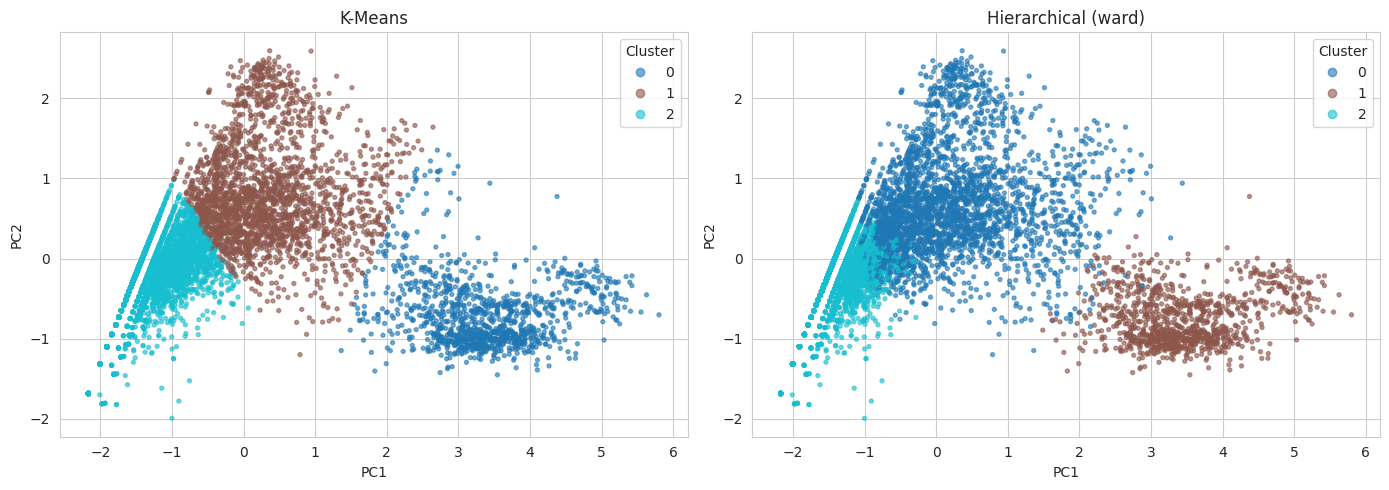

In [29]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
print('Varians dijelaskan PC1: %.2f%%, PC2: %.2f%%, total: %.2f%%' %
      (pca.explained_variance_ratio_[0]*100, pca.explained_variance_ratio_[1]*100, pca.explained_variance_ratio_.sum()*100))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, title in zip(axes, [labels_km, labels_hc], ['K-Means', f'Hierarchical ({BEST_LINKAGE})']):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='tab10', s=8, alpha=0.6)
    ax.set_title(title); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(*sc.legend_elements(), title='Cluster')
plt.tight_layout()
plt.show()


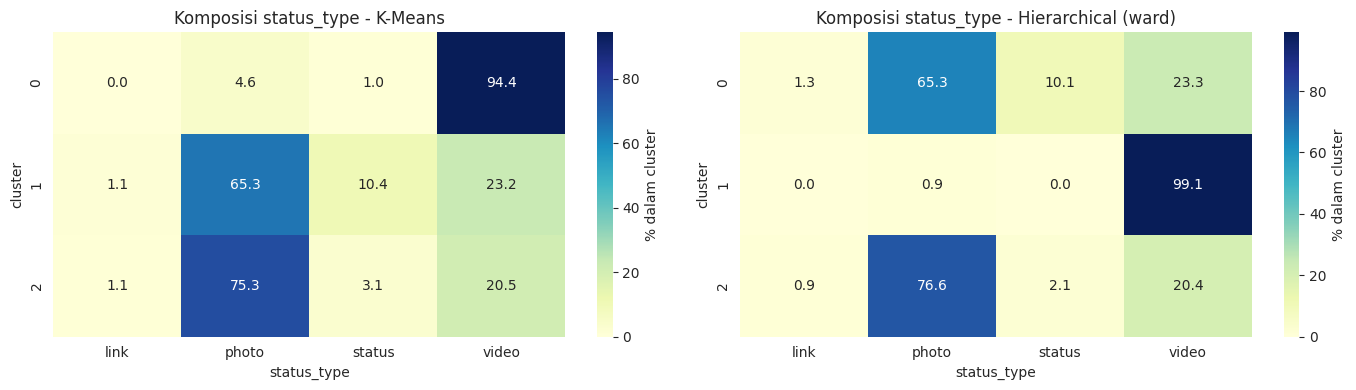

Adjusted Rand Index K-Means vs Hierarchical: 0.707


In [30]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, lab, title in zip(axes, [labels_km, labels_hc], ['K-Means', f'Hierarchical ({BEST_LINKAGE})']):
    ct = pd.crosstab(lab, meta['status_type'], normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, cbar_kws={'label': '% dalam cluster'})
    ax.set_title(f'Komposisi status_type - {title}')
    ax.set_xlabel('status_type'); ax.set_ylabel('cluster')
plt.tight_layout()
plt.show()

# Tambahan: kesepakatan antara kedua metode
from sklearn.metrics import adjusted_rand_score
print('Adjusted Rand Index K-Means vs Hierarchical:', round(adjusted_rand_score(labels_km, labels_hc), 4))


# 6. Analisis

## Analisis Hasil Eksperimen (versi ringkas)

**1. Pengaruh log dan scaling (K-Means, k=3)**

| Versi data | Ukuran cluster | Silhouette |
|---|---|---|
| Mentah | 6.392 / 467 / 137 | 0,273 |
| Scaling saja | 6.277 / 373 / 346 | 0,253 |
| Log + scaling | 3.607 / 2.258 / 1.131 | **0,464** |

- Pada data mentah, `num_comments` menyumbang 78,9% varians, jadi share dan emoji hampir diabaikan.
- Scaling saja tidak mengatasi kemiringan, sehingga outlier tetap menarik centroid.
- Hanya kombinasi log1p + scaling yang menghasilkan cluster seimbang dan Silhouette tertinggi.

**2. Kolom redundan dan sparse**
- `num_reactions` dibuang karena hampir selalu sama dengan likes + emoji (99,87% baris).
- Lima kolom emoji (60-94% bernilai nol, tidak ada sebelum 2016) digabung menjadi `num_emoji`.
- Outlier tidak dibuang karena posting viral adalah pola nyata. Dampaknya sudah ditekan oleh log1p dan scaling.

**3. Jumlah cluster**
- Elbow menunjukkan siku di k=3 secara visual (KneeLocator: k=4). Silhouette tertinggi di k=2 (0,590), sedangkan k=3 = 0,464.
- Dipilih **k=3** karena Silhouette-nya masih baik, dendrogram mendukung, dan k=2 menyembunyikan kelompok viral.

**4. Linkage**
- Ward: 0,420, cluster seimbang (dipilih).
- Average: 0,507, tetapi satu cluster hanya berisi 35 titik.
- Complete: 0,116.
- Single: [6.994, 1, 1], terjadi *chaining* karena jarak diambil dari titik terdekat.

**5. K-Means vs Ward**

| Metrik | K-Means | Ward |
|---|---|---|
| Silhouette | 0,4638 | 0,4201 |
| Davies-Bouldin (lebih rendah lebih baik) | 0,8302 | 0,8329 |
| Calinski-Harabasz | 10.935 | 9.959 |

- K-Means sedikit lebih unggul, tetapi selisihnya kecil. ARI = 0,707, jadi kedua metode cukup sepakat.
- Hasilnya mirip karena keduanya sama-sama meminimalkan varians dalam cluster.
- PCA 2 komponen menjelaskan 91,8% varians.

**6. Karakteristik cluster (K-Means)**

| Cluster | Jumlah | Median komentar / share / like | Julukan |
|---|---|---|---|
| 0 | 1.131 | 722 / 178 / 170 (video 94%) | **Viral Interaktif** |
| 1 | 2.258 | 11 / 1 / 206 | **Penarik Like** |
| 2 | 3.607 | 0 / 0 / 18 | **Sepi Interaksi** |

Ward menghasilkan pola yang sama. Video lebih sering memicu diskusi dan share, sedangkan photo lebih sering masuk cluster like saja atau sepi.

**7. Kelebihan dan kekurangan**

**K-Means:** cepat dan hemat memori, tetapi k harus ditentukan di awal, hasil bergantung inisialisasi, cluster cenderung berbentuk bola, dan sensitif terhadap outlier.

**Hierarchical:** k tidak perlu ditentukan di awal, ada dendrogram, dan hasilnya deterministik. Namun memorinya O(n²) sehingga berat untuk data besar, dan hasilnya sangat bergantung pada linkage.

# 7. Kesimpulan dan Saran

### Kesimpulan

- Transformasi log1p dan StandardScaler sangat penting untuk K-Means pada data engagement yang sangat miring. Tanpa keduanya, `num_comments` mendominasi 78,9% varians dan cluster menjadi timpang (Silhouette 0,27 dan 0,25). Dengan keduanya Silhouette naik menjadi 0,464.
- Fitur akhir adalah `num_comments`, `num_shares`, `num_likes`, dan `num_emoji` (gabungan lima emoji yang sparse). `num_reactions` dibuang karena redundan.
- Jumlah cluster yang dipilih adalah k=3: Elbow menunjukkan siku pada k=3 (KneeLocator memberi k=4), Silhouette tertinggi pada k=2 (0,590) tetapi k=3 masih baik (0,464), dan dendrogram Ward mendukung 3 cluster.
- Untuk Hierarchical Clustering, Ward dipilih karena menghasilkan cluster yang seimbang (Silhouette 0,420). Average (0,507) menghasilkan cluster berisi 35 titik, complete hanya 0,116, dan single menghasilkan [6.994, 1, 1] akibat chaining.
- K-Means sedikit lebih baik daripada Ward pada Silhouette (0,464 vs 0,420) dan Calinski-Harabasz (10.935 vs 9.959), sedangkan Davies-Bouldin hampir sama (0,830 vs 0,833). Kedua metode cukup sepakat (ARI 0,707).
- Tiga kelompok posting yang ditemukan: **Viral Interaktif** (hampir semuanya video, banyak komentar dan share), **Penarik Like** (like tinggi, interaksi aktif rendah), dan **Sepi Interaksi** (engagement rendah di semua metrik).

**Saran**
- Lakukan clustering terpisah untuk periode sebelum dan sesudah 2016, karena emoji baru ada sejak 2016 dan posting 2015 punya engagement yang sangat tinggi.
- Tambahkan fitur waktu seperti jam dan hari posting, serta `status_type` yang di-encode, untuk melihat apakah cluster berubah.
- Coba algoritma lain seperti DBSCAN (untuk mendeteksi outlier secara eksplisit) atau Gaussian Mixture Model (cluster tidak harus berbentuk bola).
- Bandingkan hasil dengan variasi hyperparameter K-Means (`n_init`, `init`) dan uji kestabilan cluster pada beberapa `random_state`.
- Evaluasi dengan sampel atau subsampling jika data jauh lebih besar, karena Hierarchical Clustering membutuhkan memori O(n²).